# Spare parts: the best score goes to a forecast of zero

**On 314 car parts, the forecast with the lowest average error says "zero" for every part in every month. A parts counter stocked to it would serve nobody.**

A parts department holds thousands of slow sellers. The typical part here sold in 11 of 51 months, one or two units at a time. Twice a year the department decides how many of each part to hold for the next six months. We compare five simple forecasters for that job and find that the winner depends on how the error is measured. Three things from TimeGym settle it: several scores recorded on the same forecasts, a score in the department's own terms, and a scorecard that shows which forecaster has learned nothing.

*Data: monthly sales of car spare parts, January 1998 to March 2002, from the Monash Time Series Forecasting Archive, CC BY 4.0 ([source and license](data/README.md#spare-parts)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import LastValueForecaster, MeanForecaster, Pipeline, cases_from_series

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The parts

One column per part, one row per month, whole units sold. Six parts are drawn below, from the slowest seller in the sample to the fastest.

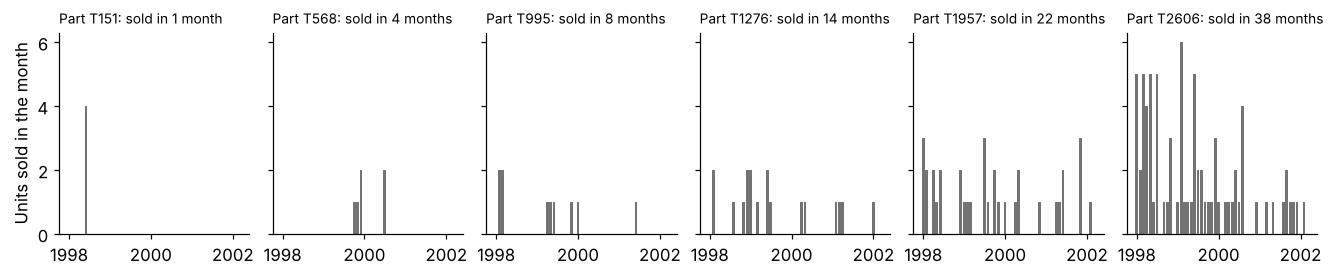

314 parts, 51 months. 75% of all part-months have no sale; the typical part sold in 11 of the 51 months.


In [2]:
parts = load("spare-parts")
months_with_a_sale = (parts > 0).sum()
shown = months_with_a_sale.sort_values(kind="stable").index[np.linspace(0, parts.shape[1] - 1, 6).astype(int)]

fig, axes = plt.subplots(1, 6, figsize=(12, 2.4), sharey=True, layout="constrained")
for ax, part in zip(axes, shown):
    ax.bar(parts.index.to_timestamp(), parts[part], width=25, color="0.45")
    sold = months_with_a_sale[part]
    ax.set_title(f"Part {part}: sold in {sold} month{'s' if sold != 1 else ''}", fontsize=9)
    ax.set_xticks(pd.to_datetime(["1998-01-01", "2000-01-01", "2002-01-01"]), ["1998", "2000", "2002"])
axes[0].set_ylabel("Units sold in the month")
plt.show()

zero_share = 100 * (parts == 0).to_numpy().mean()
print(f"{parts.shape[1]} parts, {len(parts)} months. {zero_share:.0f}% of all part-months have no sale; "
      f"the typical part sold in {int(months_with_a_sale.median())} of the {len(parts)} months.")

## Five forecasters, the same forecasts to make

Each forecaster gives the units per month for the next six months. A TimeGym model needs two methods, `fit(history)` and `predict(dates)`, so the three we write ourselves take a few lines each. The other two come with the package.

- **Always zero** ignores the history.
- **Last month** repeats the last month's sales.
- **Middle value of history** is the median: half the past months were at or below it.
- **Average of history** is the mean of every past month.
- **Average of last 12 months** is the mean of the last year.

`cases_from_series` cuts the forecasts to make: for each part, three six-month periods, each forecast from the months before it. Every forecaster then runs on the same 942 cases.

In [3]:
class AlwaysZero:
    def fit(self, history):
        return self

    def predict(self, dates):
        return np.zeros(len(dates))


class MiddleValue:
    def fit(self, history):
        self.level_ = float(np.median(np.asarray(history)))
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


class RecentAverage:
    def __init__(self, months=12):
        self.months = months

    def fit(self, history):
        self.level_ = float(np.asarray(history)[-self.months:].mean())
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


forecasters = {"Always zero": AlwaysZero(), "Last month": LastValueForecaster(),
               "Middle value of history": MiddleValue(),
               "Average of history": MeanForecaster(),
               "Average of last 12 months": RecentAverage(12)}

horizon = 6
cases = []
for part in parts.columns:
    cases += cases_from_series(parts[[part]].astype(float), origins=(33, 39, 45), horizon=horizon, name=part)
print(f"{len(cases)} cases: {parts.shape[1]} parts x 3 start months, {horizon} months ahead each.")

942 cases: 314 parts x 3 start months, 6 months ahead each.


## A score in the department's own terms

The average error is not what the parts counter cares about. It cares whether the part is on the shelf. So besides TimeGym's built-in metrics we record two of our own. Suppose the department stocks the forecast total for the six months, rounded up. `units_short` is the demand that stock could not cover, and `units_left` is what stays on the shelf at the end.

A metric is a function. TimeGym hands it what it asks for by argument name, here what was `observed` and what was `predicted`, and records the result for every case next to the built-in metrics.

In [4]:
def stock(predicted):
    "Units held for the period: the forecast total, rounded up to whole units."
    return float(np.ceil(np.sum(predicted) - 1e-9))


def units_short(observed, predicted):
    return max(float(np.sum(observed)) - stock(predicted), 0.0)


def units_left(observed, predicted):
    return max(stock(predicted) - float(np.sum(observed)), 0.0)


runs = {name: Pipeline(model).run(cases=cases, metrics={"units_short": units_short, "units_left": units_left},
                                  keep_data=True)
        for name, model in forecasters.items()}

demand = sum(float(case.observed.to_numpy().sum()) for case in cases)


def total(run, score):
    return run.metrics[score].sum()


def average(run, score):
    "The score averaged over the cases where it could be computed."
    return float(run.metrics[score].mean())


table = pd.DataFrame({name: {
    "Average error (units per month)": average(run, "mae"),
    "Scaled error": average(run, "mase"),
    "Squared error": average(run, "mse"),
    "Demand served from stock (%)": 100 * (1 - total(run, "units_short") / demand),
    "Units left on the shelf": total(run, "units_left"),
} for name, run in runs.items()}).T
display(table[["Average error (units per month)", "Scaled error"]].round(2))

by_error = table["Average error (units per month)"].sort_values()
assert by_error.index[0] == "Always zero" and table["Scaled error"].idxmin() == "Always zero"
assert table.loc["Always zero", "Scaled error"] < 0.9

,Average error (units per month),Scaled error
Always zero,0.43,0.86
Last month,0.64,1.26
Middle value of history,0.48,0.89
Average of history,0.67,1.23
Average of last 12 months,0.61,1.19


Ranked by average error, **Always zero** wins, and by a margin: it misses by 0.43 units a month where the two averages miss by more than 0.6. The scaled error agrees. It compares each forecast with the size of the part's own month-to-month changes, and a value below 1 is usually read as "better than repeating the last value". Always zero gets 0.86.

Nothing is wrong with the arithmetic. Three part-months in four have no sale, so a forecast of zero is exactly right three times in four. The average error rewards the forecast that sits at the middle value of what happens, and for these parts the middle value is zero. That is why "Middle value of history" comes second: for most parts it is the same forecast.

## The score that could not be computed

Before moving on, look at what TimeGym recorded beside the scores. The scaled error divides by the part's own past changes. A part that had never sold when the forecast was made has no changes to divide by.

In [5]:
undefined = [(entry.manifest["kind"], entry.manifest["origin"], diagnostic.message)
             for entry in runs["Always zero"].cases for diagnostic in entry.diagnostics
             if diagnostic.name == "metric_mase" and str(diagnostic.status) == "INCONCLUSIVE"]
for part, month, message in undefined:
    print(f"Part {part}, forecast made at {month}: {message}")

counts = runs["Always zero"].report.summary["status_counts"]
print(f"\nOutput checks passed: {counts['PASS']}, failed: {counts['FAIL']}, models that raised an error: {counts['ERROR']}.")
runs["Always zero"].assert_passed()   # stop here if any forecast crashed or failed a check; an undefined MASE is neither
assert len(undefined) == 3

Part T451, forecast made at 2000-09: MASE is undefined for a zero naive-error denominator
Part T451, forecast made at 2001-03: MASE is undefined for a zero naive-error denominator
Part T451, forecast made at 2001-09: MASE is undefined for a zero naive-error denominator

Output checks passed: 942, failed: 0, models that raised an error: 0.


Part T451 had not sold a single unit by any of its three forecast dates, so three cases have no scaled error. TimeGym says so and says why. It did not put infinity or a made-up number in the table, and it did not drop the cases without telling us: their other scores are all there. The "Scaled error" column above is an average over the 939 cases where the score exists, and now we know that.

With 942 cases this hardly moves the average. In the full dataset of 2,674 parts, or with a shorter history, the parts that had not sold yet are a large group, and a pipeline that quietly skips them or averages in an infinity gives a different ranking without any warning.

## Two more ways to measure

Now the same forecasts measured by the squared error, which punishes a large miss much more than a small one, and by what the parts counter sees.

,Squared error,Demand served from stock (%),Units left on the shelf
Always zero,1.41,0.0,0.0
Last month,2.01,31.0,1638.0
Middle value of history,1.38,23.0,488.0
Average of history,1.29,67.0,1830.0
Average of last 12 months,1.17,69.0,1274.0


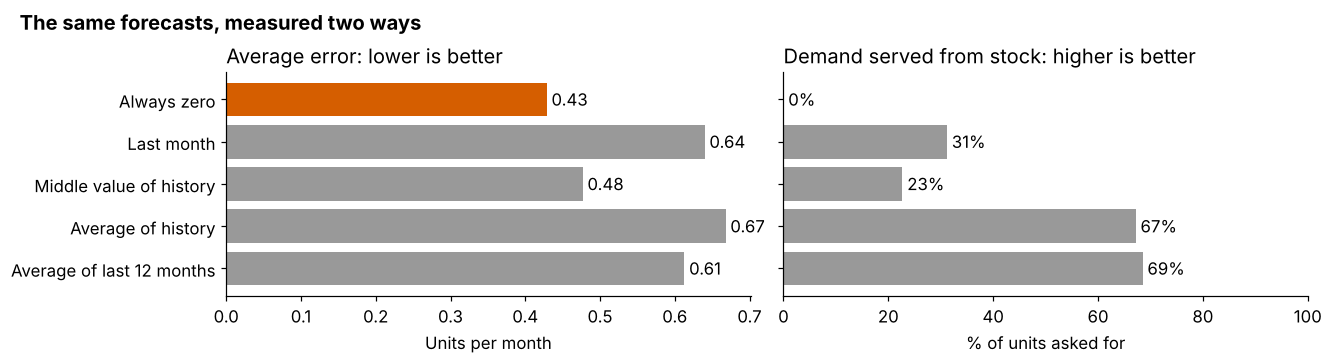

In [6]:
display(table[["Squared error", "Demand served from stock (%)", "Units left on the shelf"]]
        .round({"Squared error": 2, "Demand served from stock (%)": 0, "Units left on the shelf": 0}))

colors = ["#D55E00" if name == "Always zero" else "0.6" for name in table.index]
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.2), layout="constrained")
left.barh(table.index, table["Average error (units per month)"], color=colors)
left.set(title="Average error: lower is better", xlabel="Units per month")
right.barh(table.index, table["Demand served from stock (%)"], color=colors)
right.set(title="Demand served from stock: higher is better", xlabel="% of units asked for", xlim=(0, 100))
right.tick_params(labelleft=False)
for ax, column, form in ((left, "Average error (units per month)", "{:.2f}"), (right, "Demand served from stock (%)", "{:.0f}%")):
    ax.invert_yaxis()
    for row, value in enumerate(table[column]):
        ax.text(value, row, " " + form.format(value), va="center")
fig.suptitle("The same forecasts, measured two ways", x=0.01, ha="left", fontweight="bold")
plt.show()

assert table["Squared error"].idxmin() == "Average of last 12 months"
assert table.loc["Always zero", "Demand served from stock (%)"] == 0
served = table["Demand served from stock (%)"]
assert served["Average of last 12 months"] > 65 and served["Average of history"] > 65
assert table.loc["Average of last 12 months", "Units left on the shelf"] < table.loc["Average of history", "Units left on the shelf"]

The ranking turns over. By squared error the average of the last 12 months is best and Always zero is fourth of five. At the parts counter, Always zero serves 0% of demand, because it stocks nothing. The two averages serve about two thirds of it, and the 12-month average does it with about 550 fewer units left on the shelf than the average of all history. Sales of these parts were falling over the four years, so the recent months are the better guide.

The parts counter's score is the one that matters, and it took a few lines to write. The department would tune the rule it stands for: this one holds no safety stock, which is why a third of demand still goes unserved.

## A check that does not depend on the score

There is another way to see that Always zero is not a forecaster, and it needs no opinion about which score is right. The scorecard runs a forecaster on generated series where the answer is known, such as noise around a fixed level of 10. A forecaster that reads its history gets that one right.

In [7]:
zero_card = Pipeline(AlwaysZero(), name="Always zero").run(history_length=45, horizon=horizon).scorecard
recent_card = Pipeline(RecentAverage(12), name="Average of last 12 months").run(history_length=45, horizon=horizon).scorecard

side_by_side = pd.DataFrame({
    "Kind of series": zero_card.table["title"], "Noise": zero_card.table["noise"],
    "Always zero": zero_card.table["score"], "Average of last 12 months": recent_card.table["score"],
    "What Always zero gets wrong": zero_card.table["mistakes"],
}).set_index(["Kind of series", "Noise"]).round(0)
side_by_side[["Always zero", "Average of last 12 months"]] = side_by_side[["Always zero", "Average of last 12 months"]].astype(int)
display(side_by_side)
print(f"Overall: Always zero {zero_card.score:.0f}, Average of last 12 months {recent_card.score:.0f}.")

level = side_by_side.loc["Noise around a fixed level"]
assert (level["Always zero"] < 10).all() and (level["Average of last 12 months"] > 85).all()
assert (level["What Always zero gets wrong"] == "Forecasts too low").all()
assert zero_card.score < 40 < recent_card.score

Always zero  \
Kind of series                      Noise                     
Pure noise                          Low noise           100   
                                    High noise          100   
Noise around a fixed level          Low noise             0   
                                    High noise            4   
Straight-line trend                 Low noise             1   
                                    High noise           15   
Repeating seasonal cycle            Low noise             5   
                                    High noise           47   
Trend + seasonal cycle              Low noise             1   
                                    High noise           15   
Sudden level shift                  Low noise             1   
                                    High noise           10   
Mean reversion (AR(1)): shocks fade Low noise            69   
                                    High noise           89   
Irregular cycles (AR(2))            Low noise            46   
                                    High noise           69   
Random walk: shocks never fade      Low noise             8   
                                    High noise           30   
Random walk with drift              Low noise             7   
                                    High noise           25   

                                                Average of last 12 months  \
Kind of series                      Noise                                   
Pure noise                          Low noise                          94   
                                    High noise                         94   
Noise around a fixed level          Low noise                          94   
                                    High noise                         94   
Straight-line trend                 Low noise                          21   
                                    High noise                         74   
Repeating seasonal cycle            Low noise                           5   
                                    High noise                         46   
Trend + seasonal cycle              Low noise                           5   
                                    High noise                         43   
Sudden level shift                  Low noise                          54   
                                    High noise                         90   
Mean reversion (AR(1)): shocks fade Low noise                          75   
                                    High noise                         87   
Irregular cycles (AR(2))            Low noise                          31   
                                    High noise                         46   
Random walk: shocks never fade      Low noise                          52   
                                    High noise                         92   
Random walk with drift              Low noise                          53   
                                    High noise                         86   

                                                               What Always zero gets wrong  
Kind of series                      Noise                                                   
Pure noise                          Low noise                                               
                                    High noise                                              
Noise around a fixed level          Low noise                            Forecasts too low  
                                    High noise                           Forecasts too low  
Straight-line trend                 Low noise                            Forecasts too low  
                                    High noise                           Forecasts too low  
Repeating seasonal cycle            Low noise                               Trend too flat  
                                    High noise                              Trend too flat  
Trend + seasonal cycle              

Overall: Always zero 32, Average of last 12 months 62.


On noise around a fixed level, the easiest row there is, Always zero scores 0 and 4 out of 100, and the card names the mistake: forecasts too low. The 12-month average scores 94. Always zero gets full marks only on pure noise around zero, where zero happens to be the answer. Overall it is 32 against 62.

The 12-month average has weak rows too. It cannot follow a trend or a seasonal cycle, and the card says so. For parts that sell twice a year there is little of either to follow, so a level is most of what there is to learn, and this forecaster learns it.

## What TimeGym added

- Several scores on exactly the same 942 forecasts, in one run. Seen side by side, the average error and the squared error name different winners, which is the warning.
- A plain statement of where a score does not exist. Three cases had no scaled error, and they were reported and left out of that score only.
- The department's own measure as a score, recorded per case like any other. It turned "which error measure?" into "which forecaster keeps parts on the shelf?".
- A scorecard that exposed the leaderboard's winner without using any error measure on this data.

## Change one thing

- Hold safety stock: in `stock`, add one unit, or multiply the total by 1.5, and watch demand served and units left move in opposite directions.
- Change `RecentAverage(12)` to 6 or 24 months and compare all three scores.
- Forecast one month ahead with `horizon=1` and see whether any ranking changes.
- `load("spare-parts", full=True)` has all 2,674 parts. The 165 without figures after early 1999 need dropping first: `parts.dropna(axis=1)`.

**What this doesn't show.** The stock rule is the simplest one possible: no safety stock, no cost of holding a part or of losing a sale, no delivery time. Methods built for demand that comes in rare lumps were not tried. TimeGym has no score made for counts; a forecaster that returns a range rather than one number can be scored with `pinball`, which is closer to how stock is really set. The parts carry the archive's labels, so we cannot say what any of them is.

**Related:** [Your own metrics](../docs/api/diagnostics.md#your-own-metrics) in the reference, [When there is no score](../docs/concepts/scope.md#when-there-is-no-score), [Custom model](../tutorials/02_custom_model.ipynb) for the `fit` and `predict` a model needs, and [Weekly shop sales](store-sales.ipynb) for products that sell every week. More examples are on the [examples page](../docs/examples.md).